# Лабораторна робота № 8
## Методи кластеризації та класифікації: Iris, K-Means, PCA

**Мета:** дослідити кластеризацію Iris та студентських даних, порівняти три класифікатори й застосувати PCA.

**Підхід:** Послідовний аналіз показників і візуальна перевірка результату. Висновки друкуються за реально отриманими показниками. Для отримання всіх графіків запустіть комірки зверху вниз у Colab із доступом до інтернету.



### Підготовка бібліотек
Для зовнішнього набору використовується відкритий KaggleHub; за наявності CSV у робочій папці його можна використати замість завантаження.

In [1]:
%pip -q install kagglehub kneed yellowbrick

In [2]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from kneed import KneeLocator
from yellowbrick.cluster import KElbowVisualizer

plt.style.use('classic')
RANDOM_STATE = 42
PALETTE = 'viridis'
LINE_COLOR = '#167bca'
CENTER_COLOR = '#d64d42'
print('Бібліотеки імпортовано. Стиль:', 'classic')


Бібліотеки імпортовано. Стиль: classic


## Завдання 1. Кластеризація Iris
**1.1–1.2.** Підготуємо імпорти та завантажимо Iris; для кластеризації використаємо **перші три** числові ознаки з масштабуванням.

In [3]:
iris_bundle = load_iris(as_frame=True)
iris_table = iris_bundle.data
iris_features = iris_table.iloc[:, :3]
iris_scaled = StandardScaler().fit_transform(iris_features)
print('Форма:', iris_table.shape, '| взято ознаки:', list(iris_features.columns))
display(iris_table.head())


Форма: (150, 4) | взято ознаки: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3–1.4.** Обчислення WCSS для K=1…10 і силуетів для K=2…10 окремими циклами.

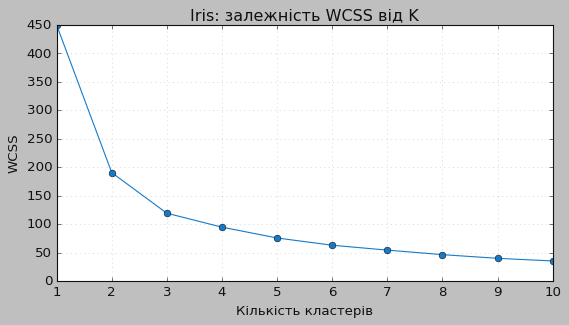

In [4]:
k_values = np.arange(1, 11)
iris_inertia = []

for n_clusters in k_values:
    fitted = KMeans(n_clusters=n_clusters, n_init=10, random_state=RANDOM_STATE).fit(
        iris_scaled)
    iris_inertia.append(fitted.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_values, iris_inertia, 'o-', color=LINE_COLOR)
plt.xticks(k_values)
plt.title('Iris: залежність WCSS від K')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.grid(alpha=0.25)
plt.show()


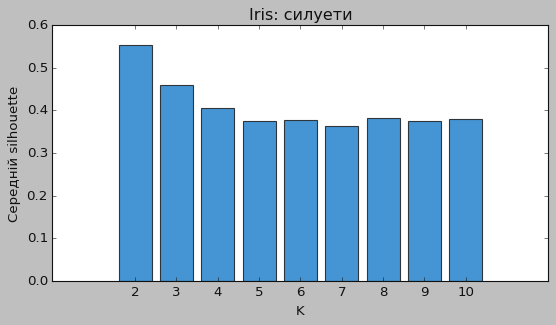

Максимум силуета: K = 2 , значення: 0.5525


In [5]:
iris_sil = {}
for k in range(2, 11):
    predicted = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(
        iris_scaled)
    iris_sil[k] = silhouette_score(iris_scaled, predicted)

plt.figure(figsize=(8, 4))
plt.bar(list(iris_sil), list(iris_sil.values()), color=LINE_COLOR, alpha=0.8)
plt.xticks(list(iris_sil))
plt.ylabel('Середній silhouette')
plt.xlabel('K')
plt.title('Iris: силуети')
plt.show()
best_iris_k = max(iris_sil, key=iris_sil.get)
print('Максимум силуета: K =', best_iris_k, ', значення:', round(iris_sil[best_iris_k],
    4))


In [6]:
iris_elbow = (
    KneeLocator(np.arange(1, 11), iris_inertia, curve='convex', direction='decreasing')
        .knee
)
print('Метод ліктя для Iris (WCSS):', iris_elbow if iris_elbow is not None
    else 'немає чіткої точки')


Метод ліктя для Iris (WCSS): 3


**1.5.** Фінальна модель **K-Means з двома кластерами** навчається за трьома ознаками. На графіку показано лише перші дві координати та проєкції центрів.

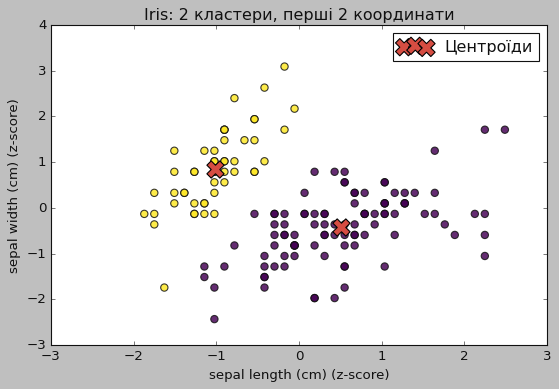

Кількість у двох кластерах: [100, 50]


In [7]:
iris_final = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
iris_groups = iris_final.fit_predict(iris_scaled)
fig, ax = plt.subplots(figsize=(8, 5))
plotted = (
    ax.scatter(iris_scaled[:, 0], iris_scaled[:, 1], c=iris_groups, cmap=PALETTE,
        marker='o', s=43, alpha=0.83)
)
ax.scatter(iris_final.cluster_centers_[:, 0], iris_final.cluster_centers_[:, 1], s=240,
    c=CENTER_COLOR, marker='X', edgecolor='black', label='Центроїди')
ax.set(xlabel=iris_features.columns[0] + ' (z-score)', ylabel=iris_features.columns[1]
    + ' (z-score)', title='Iris: 2 кластери, перші 2 координати')
ax.legend()
plt.show()
print('Кількість у двох кластерах:', np.bincount(iris_groups).tolist())


## Завдання 2. Дані про успішність студентів
**2.1–2.2.** Завантажимо `rabieelkharoua/students-performance-dataset` із Kaggle або відкриємо локальний CSV. Встановимо імпорти, потрібні для класифікації та кластеризації.

In [8]:
from glob import glob

local_paths = [
    f
    for pattern in (
        'Student_data.csv',
        'Student_performance_data*.csv',
        '/content/Student_data.csv',
        '/content/Student_performance_data*.csv',
    )
    for f in glob(pattern)
]

if local_paths:
    student_csv = local_paths[0]
    print('Локальний файл:', student_csv)
else:
    import kagglehub
    dataset_dir = kagglehub.dataset_download(
        'rabieelkharoua/students-performance-dataset')
    csv_files = sorted(Path(dataset_dir).rglob('*.csv'))
    if not csv_files:
        raise FileNotFoundError('Не знайдено CSV у каталозі KaggleHub')
    student_csv = csv_files[0]
    print('Дані KaggleHub:', student_csv)

students = pd.read_csv(student_csv)
needed = {'StudentID', 'GradeClass', 'Age', 'StudyTimeWeekly', 'Absences', 'GPA'}
assert needed.issubset(students.columns), 'У CSV відсутні необхідні стовпці'
print('Розмір:', students.shape)


100%|██████████| 66.2k/66.2k [00:00<00:00, 32.8MB/s]

Extracting files...
Дані KaggleHub: /root/.cache/kagglehub/datasets/rabieelkharoua/students-performance-dataset/versions/2/Student_performance_data _.csv
Розмір: (2392, 15)


**2.3–2.8.** Первинний аналіз: приклади записів, назви й типи стовпців, пропуски, дублікати, статистики.

In [9]:
display(students.head())
print('Стовпці:', students.columns.tolist())
print('Типи даних:')
students.info()
print('\nПропуски:')
print(students.isna().sum().to_string())
print('\nКількість дублікатів:', students.duplicated().sum())
display(students.describe().T.round(2))


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


Стовпці: ['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']
Типи даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64 

,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.50,690.66,1001.0,1598.75,2196.50,2794.25,3392.00
Age,2392.0,16.47,1.12,15.0,15.00,16.00,17.00,18.00
Gender,2392.0,0.51,0.50,0.0,0.00,1.00,1.00,1.00
Ethnicity,2392.0,0.88,1.03,0.0,0.00,0.00,2.00,3.00
ParentalEducation,2392.0,1.75,1.00,0.0,1.00,2.00,2.00,4.00
StudyTimeWeekly,2392.0,9.77,5.65,0.0,5.04,9.71,14.41,19.98
Absences,2392.0,14.54,8.47,0.0,7.00,15.00,22.00,29.00
Tutoring,2392.0,0.30,0.46,0.0,0.00,0.00,1.00,1.00
ParentalSupport,2392.0,2.12,1.12,0.0,1.00,2.00,3.00,4.00
Extracurricular,2392.0,0.38,0.49,0.0,0.00,0.00,1.00,1.00


**2.9.** Ціль `GradeClass`; службовий `StudentID` виключаємо. Розбиття 80/20 зі `random_state=42` та стратифікацією. Масштабування для LR/SVM — **всередині Pipeline**, щоб не підглядати в CV-валідацію.

In [10]:
features = students.drop(columns=['StudentID', 'GradeClass'])
target = students['GradeClass']
X_train, X_test, y_train, y_test = (
    train_test_split(features, target, test_size=0.2, random_state=RANDOM_STATE,
        stratify=target)
)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print('Навчальні:', X_train.shape, 'Тестові:', X_test.shape)
print('Цільова змінна:', target.value_counts().sort_index().to_dict())


Навчальні: (1913, 13) Тестові: (479, 13)
Цільова змінна: {0.0: 107, 1.0: 269, 2.0: 391, 3.0: 414, 4.0: 1211}


**2.10. Random Forest.** Підбираємо кількість дерев, глибину та мінімальний розмір листка.

In [11]:
rf_search = (
    GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), {
        'n_estimators': [90, 150], 'max_depth': [8, None], 'min_samples_leaf': [1, 3]},
        cv=folds, scoring='accuracy', n_jobs=-1)
)
rf_search.fit(X_train, y_train)
print('RF:', rf_search.best_params_, 'CV=', round(rf_search.best_score_, 4))


RF: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 90} CV= 0.9216


**2.11. Logistic Regression.** Регуляризація та баланс класів, стандартизація у pipeline.

In [12]:
lr_search = (
    GridSearchCV(Pipeline([('scale', StandardScaler()), ('model', LogisticRegression(
        solver='lbfgs', max_iter=2000))]), {'model__C': [0.3, 1.5],
        'model__class_weight': [None, 'balanced']}, cv=folds, scoring='accuracy',
        n_jobs=-1)
)
lr_search.fit(X_train, y_train)
print('LR:', lr_search.best_params_, 'CV=', round(lr_search.best_score_, 4))


LR: {'model__C': 1.5, 'model__class_weight': None} CV= 0.7867


**2.12. SVM.** Перевіримо лінійне та RBF-ядра.

In [13]:
svm_search = (
    GridSearchCV(Pipeline([('scale', StandardScaler()), ('model', SVC())]), {
        'model__C': [0.5, 2.0], 'model__kernel': ['linear', 'rbf']}, cv=folds,
        scoring='accuracy', n_jobs=-1)
)
svm_search.fit(X_train, y_train)
print('SVM:', svm_search.best_params_, 'CV=', round(svm_search.best_score_, 4))


SVM: {'model__C': 2.0, 'model__kernel': 'linear'} CV= 0.85


**2.13.** Порівняння на тестовій вибірці. Модель для `classification_report` визначається **лише за CV accuracy**, а не за тестом.

In [14]:
model_pairs = [('Random Forest', rf_search), ('Logistic Regression', lr_search), ('SVM',
    svm_search)]
benchmark = (
    pd.DataFrame([{'Модель': name, 'CV accuracy': search.best_score_,
        'Test accuracy': accuracy_score(y_test, search.predict(X_test))} for name,
        search in model_pairs])
)
display(benchmark.round(4).sort_values('CV accuracy', ascending=False))
winner_name, winner_search = max(model_pairs, key=lambda pair: pair[1].best_score_)
print('Найкраща за CV:', winner_name)
print(classification_report(y_test, winner_search.predict(X_test), zero_division=0))


,Модель,CV accuracy,Test accuracy
0,Random Forest,0.9216,0.9102
2,SVM,0.8500,0.8559
1,Logistic Regression,0.7867,0.7954


Найкраща за CV: Random Forest
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



**2.14–2.15.** Для **чотирьох** ознак `Age`, `StudyTimeWeekly`, `Absences`, `GPA` стандартизуємо дані й порівняємо WCSS (K=1…10) та силуети (K=2…10). Мітки `GradeClass` при кластеризації не використовуємо.

In [15]:
study_columns = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
student_matrix = StandardScaler().fit_transform(students[study_columns])
student_k = np.arange(1, 11)
student_inertia, student_sil = ([], [])

for n in student_k:
    km = KMeans(n_clusters=n, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(student_matrix)
    student_inertia.append(km.inertia_)
    if n >= 2:
        student_sil.append(silhouette_score(student_matrix, labels))

student_best_k = int(np.argmax(student_sil) + 2)
print('Найкраще K за силуетом:', student_best_k)
print('Показник:', round(max(student_sil), 4))


Найкраще K за силуетом: 2
Показник: 0.308


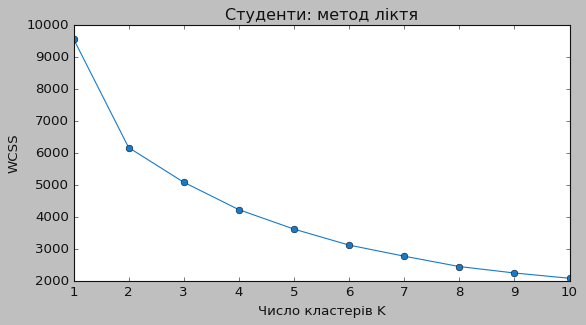

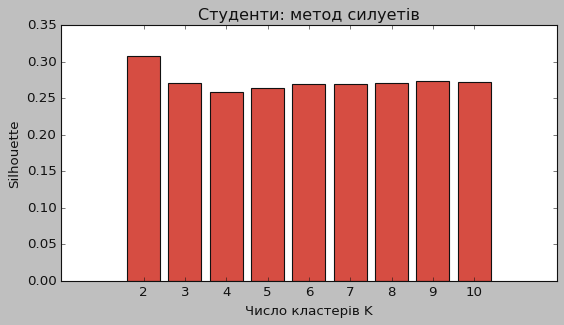

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(student_k, student_inertia, 'o-', color=LINE_COLOR)
ax.set(xlabel='Число кластерів K', ylabel='WCSS', title='Студенти: метод ліктя')
ax.set_xticks(student_k)
plt.show()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(np.arange(2, 11), student_sil, color=CENTER_COLOR)
ax.set(xlabel='Число кластерів K', ylabel='Silhouette',
    title='Студенти: метод силуетів')
ax.set_xticks(np.arange(2, 11))
plt.show()


In [17]:
student_elbow = (
    KneeLocator(student_k, student_inertia, curve='convex', direction='decreasing').knee
)
print('Метод ліктя для 4 ознак студентів:', student_elbow if student_elbow is not None
    else 'немає чіткого зламу')


Метод ліктя для 4 ознак студентів: 4


**2.16. PCA та автоматичний пошук ліктя.** У PCA передаємо **всі ознаки, крім `StudentID` і `GradeClass`**. Будуємо частку поясненої дисперсії, пробуємо `KneeLocator`, кумулятивну криву; якщо точку ліктя не знайдено — беремо кількість компонент, що пояснює не менше 90% дисперсії. Кластеризуємо **саме PCA-представлення** у `KElbowVisualizer`.

In [18]:
all_student_features = students.drop(columns=['StudentID', 'GradeClass'])
scaled_all = StandardScaler().fit_transform(all_student_features)
full_pca = PCA().fit(scaled_all)
variance_ratio = full_pca.explained_variance_ratio_
components_axis = np.arange(1, len(variance_ratio) + 1)
cumulative = np.cumsum(variance_ratio)
knee_obj = (
    KneeLocator(components_axis, variance_ratio, curve='convex', direction='decreasing')
)
knee_point = knee_obj.knee
n_components = (
    int(knee_point) if knee_point is not None else int(np.searchsorted(cumulative, 0.9)
        + 1)
)
print('Частки дисперсії:', np.round(variance_ratio, 4))
print('KneeLocator:', knee_point, '| Обрано компонент:', n_components)
print('Кумулятивна частка:', round(float(cumulative[n_components - 1]), 4))
assert 1 <= n_components <= len(variance_ratio)
pcs = PCA(n_components=n_components).fit_transform(scaled_all)


Частки дисперсії: [0.1525 0.0861 0.0827 0.0807 0.0786 0.0779 0.0763 0.076  0.0744 0.0738
 0.0717 0.0675 0.0018]
KneeLocator: 2 | Обрано компонент: 2
Кумулятивна частка: 0.2386


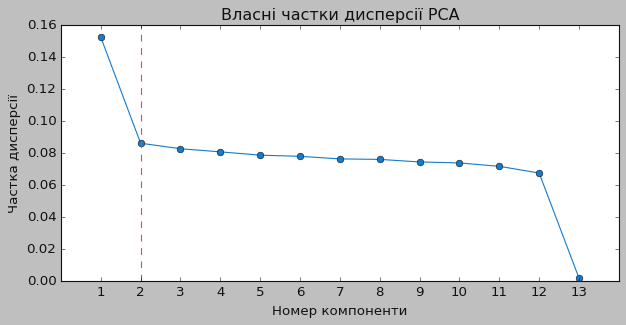

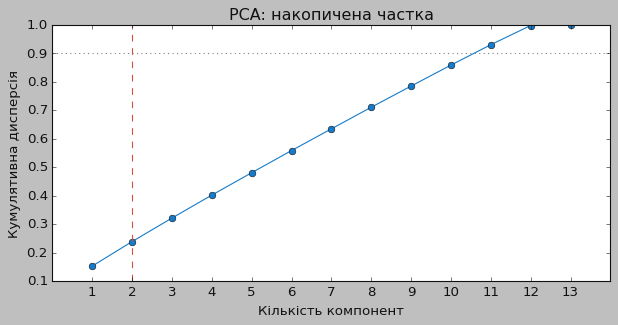

In [19]:
plt.figure(figsize=(9, 4))
plt.plot(components_axis, variance_ratio, 'o-', color=LINE_COLOR)
plt.axvline(n_components, color=CENTER_COLOR, ls='--')
plt.xticks(components_axis)
plt.xlabel('Номер компоненти')
plt.ylabel('Частка дисперсії')
plt.title('Власні частки дисперсії PCA')
plt.show()
plt.figure(figsize=(9, 4))
plt.plot(components_axis, cumulative, 'o-', color=LINE_COLOR)
plt.axvline(n_components, color=CENTER_COLOR, ls='--')
plt.axhline(0.9, color='gray', ls=':')
plt.xticks(components_axis)
plt.xlabel('Кількість компонент')
plt.ylabel('Кумулятивна дисперсія')
plt.title('PCA: накопичена частка')
plt.show()


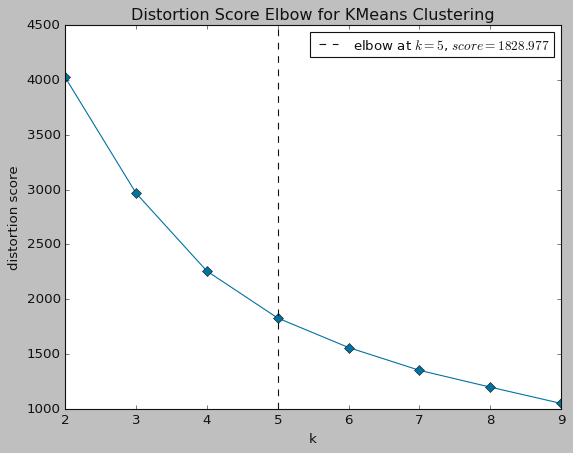

Кластери після PCA за KElbowVisualizer: 5


In [20]:
elbow_pca = (
    KElbowVisualizer(KMeans(n_init=10, random_state=RANDOM_STATE), k=(2, 10),
        timings=False)
)
elbow_pca.fit(pcs)
elbow_pca.show()
print('Кластери після PCA за KElbowVisualizer:', elbow_pca.elbow_value_)


## Висновки


In [23]:
print(
    f"Під час роботи я перевірив кластеризацію Iris "
    f"та даних студентів. Для студентів отримав "
    f"{student_best_k} кластерів за методом силуетів. "
    f"Серед класифікаторів найкращим виявився {winner_name}. "
    "Також я використав PCA для зменшення кількості ознак."
)

Під час роботи я перевірив кластеризацію Iris та даних студентів. Для студентів отримав 2 кластерів за методом силуетів. Серед класифікаторів найкращим виявився Random Forest. Також я використав PCA для зменшення кількості ознак.
